# REESTRUCTURACIÓN Y PREPARACIÓN DE DATOS NORMALIZADOS

En esta sección preparamos los conjuntos de datos normalizándolos (dividiendo por 255.0) y definiendo de manera clara variables independientes para la Red Densa (`model_dense`) y la Red Convolucional (`model_conv`).

In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Cargar y normalizar datos
(x_train_raw, y_train), (x_test_raw, y_test) = tf.keras.datasets.mnist.load_data()

# Normalización a rango [0, 1]
x_train_norm = x_train_raw.astype('float32') / 255.0
x_test_norm = x_test_raw.astype('float32') / 255.0

# Preparar dimensiones para Red Densa (aplanado)
x_train_dense = x_train_norm.reshape(x_train_norm.shape[0], 28 * 28)
x_test_dense = x_test_norm.reshape(x_test_norm.shape[0], 28 * 28)

# Preparar dimensiones para Red Convolucional (añadiendo canal de color)
x_train_conv = x_train_norm[..., np.newaxis]
x_test_conv = x_test_norm[..., np.newaxis]

print("Datos preparados y normalizados:")
print(f"Densa - Train: {x_train_dense.shape}, Test: {x_test_dense.shape}")
print(f"Conv - Train: {x_train_conv.shape}, Test: {x_test_conv.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Datos preparados y normalizados:
Densa - Train: (60000, 784), Test: (10000, 784)
Conv - Train: (60000, 28, 28, 1), Test: (10000, 28, 28, 1)


## Definición y Entrenamiento de la Red Densa

In [3]:
# Construcción del modelo denso
in_dense = tf.keras.layers.Input(shape=(784,))
cp1_dense = tf.keras.layers.Dense(64, activation='relu')(in_dense)
cp2_dense = tf.keras.layers.Dense(64, activation='relu')(cp1_dense)
out_dense = tf.keras.layers.Dense(10, activation='softmax')(cp2_dense)
model_dense = tf.keras.Model(inputs=in_dense, outputs=out_dense, name="Modelo_Denso")

model_dense.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

print("Entrenando Red Densa...")
history_dense = model_dense.fit(x_train_dense, y_train, validation_split=0.1, epochs=15, batch_size=32, verbose=1)

Entrenando Red Densa...
Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.9173 - loss: 0.2818 - val_accuracy: 0.9638 - val_loss: 0.1228
Epoch 2/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9624 - loss: 0.1249 - val_accuracy: 0.9667 - val_loss: 0.1082
Epoch 3/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9724 - loss: 0.0905 - val_accuracy: 0.9698 - val_loss: 0.0968
Epoch 4/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9768 - loss: 0.0722 - val_accuracy: 0.9670 - val_loss: 0.1045
Epoch 5/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9810 - loss: 0.0586 - val_accuracy: 0.9757 - val_loss: 0.0826
Epoch 6/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9845 - loss: 0.0497 - val_accuracy: 0.9747 - val_loss: 0.0891
Epoch 7/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9867 - loss: 0.0415 - val_accuracy: 0.9800 - val_loss: 0.0793
Epoch 8/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy:

## Definición y Entrenamiento de la Red Convolucional

In [4]:
# Construcción del modelo convolucional
in_conv = tf.keras.layers.Input(shape=(28, 28, 1), name="Input")
conv1_c = tf.keras.layers.Conv2D(32, kernel_size=3, activation='relu', strides=1, padding="same", name="Convolucion_1")(in_conv)
max1_c = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name="Pooling_1")(conv1_c)
conv2_c = tf.keras.layers.Conv2D(64, kernel_size=3, activation='relu', strides=1, padding="same", name="Convolucion_2")(max1_c)
max2_c = tf.keras.layers.MaxPooling2D(pool_size=(2, 2), name="Pooling_2")(conv2_c)
flat_c = tf.keras.layers.Flatten(name="Flatten")(max2_c)
out_conv = tf.keras.layers.Dense(10, activation='softmax', name="Densa")(flat_c)

model_conv = tf.keras.Model(inputs=in_conv, outputs=out_conv, name="Modelo_Convolucional")

model_conv.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

print("Entrenando Red Convolucional...")
history_conv = model_conv.fit(x_train_conv, y_train, validation_split=0.1, epochs=15, batch_size=32, verbose=1)

Entrenando Red Convolucional...
Epoch 1/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 7ms/step - accuracy: 0.9546 - loss: 0.1552 - val_accuracy: 0.9830 - val_loss: 0.0601
Epoch 2/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9832 - loss: 0.0542 - val_accuracy: 0.9885 - val_loss: 0.0410
Epoch 3/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9881 - loss: 0.0383 - val_accuracy: 0.9903 - val_loss: 0.0386
Epoch 4/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9906 - loss: 0.0296 - val_accuracy: 0.9900 - val_loss: 0.0367
Epoch 5/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9927 - loss: 0.0223 - val_accuracy: 0.9893 - val_loss: 0.0365
Epoch 6/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9940 - loss: 0.0179 - val_accuracy: 0.9913 - val_loss: 0.0344
Epoch 7/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9958 - loss: 0.0135 - val_accuracy: 0.9898 - val_loss: 0.0396
Epoch 8/15
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - a

# COMPARATIVA DE RENDIMIENTO

Evaluamos ambos modelos sobre el conjunto de prueba para contrastar de manera directa sus métricas.


In [5]:
import pandas as pd

# Evaluar modelos
loss_dense_test, acc_dense_test = model_dense.evaluate(x_test_dense, y_test, verbose=0)
loss_conv_test, acc_conv_test = model_conv.evaluate(x_test_conv, y_test, verbose=0)

# Obtener métricas finales del historial de entrenamiento
loss_dense_train = history_dense.history['loss'][-1]
acc_dense_train = history_dense.history['accuracy'][-1]
loss_conv_train = history_conv.history['loss'][-1]
acc_conv_train = history_conv.history['accuracy'][-1]

# Construir tabla comparativa
data_comparativa = {
    'Modelo': ['Red Densa (model_dense)', 'Red Convolucional (model_conv)'],
    'Loss (Entrenamiento)': [loss_dense_train, loss_conv_train],
    'Accuracy (Entrenamiento)': [acc_dense_train, acc_conv_train],
    'Loss (Prueba)': [loss_dense_test, loss_conv_test],
    'Accuracy (Prueba)': [acc_dense_test, acc_conv_test]
}

df_comparativa = pd.DataFrame(data_comparativa)
display(df_comparativa)

,Modelo,Loss (Entrenamiento),Accuracy (Entrenamiento),Loss (Prueba),Accuracy (Prueba)
0,Red Densa (model_dense),0.013992,0.994981,0.103787,0.9776
1,Red Convolucional (model_conv),0.004772,0.998204,0.047878,0.9892


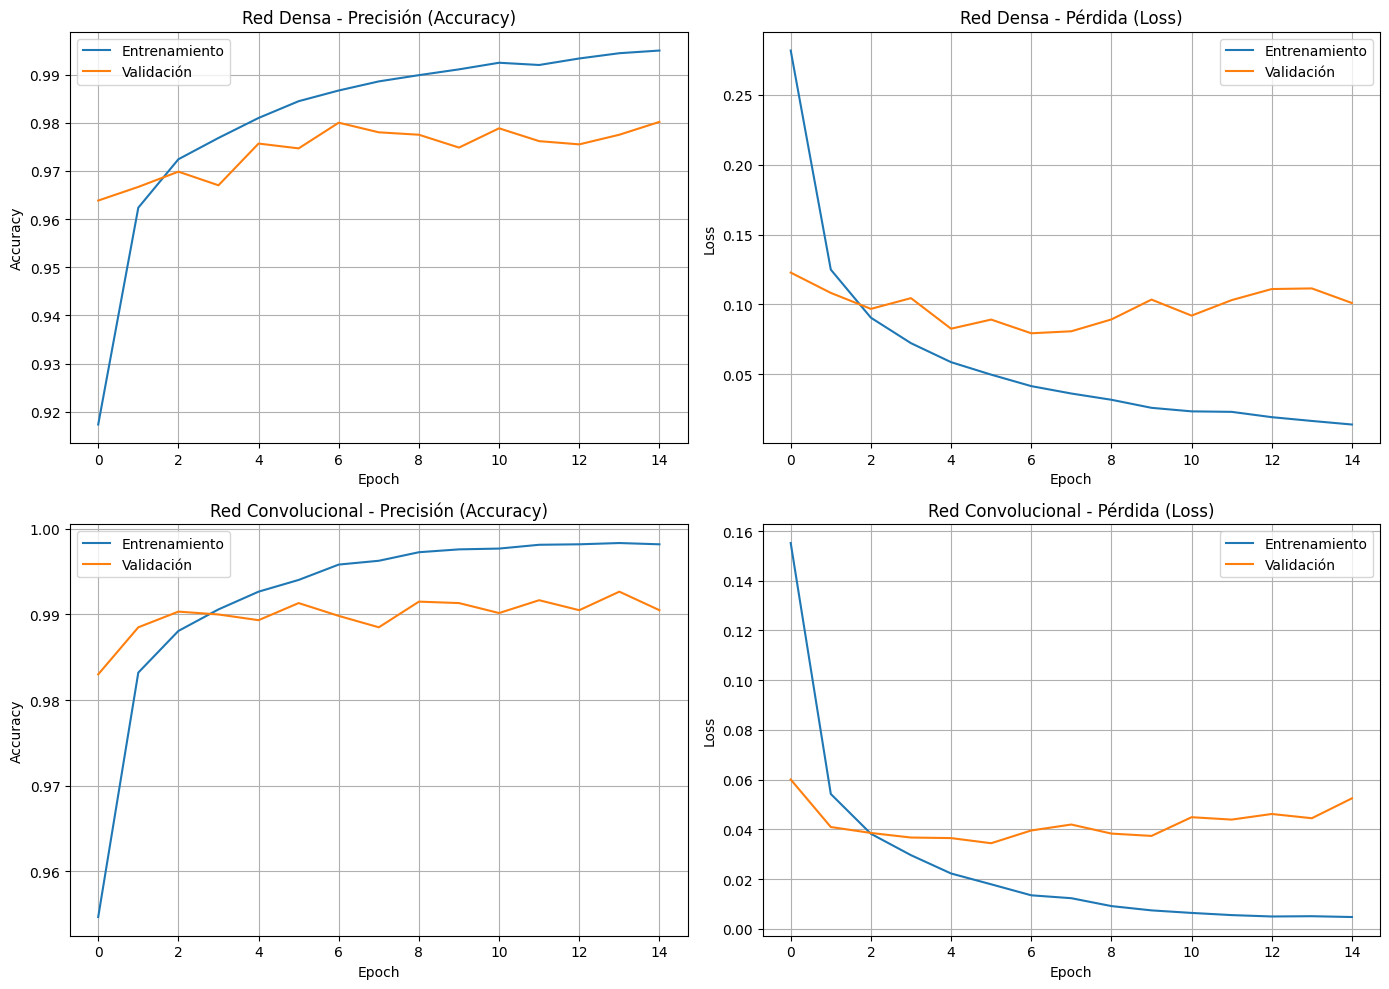

In [6]:
# Graficar Curvas de Aprendizaje
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Red Densa - Accuracy
axs[0, 0].plot(history_dense.history['accuracy'], label='Entrenamiento')
axs[0, 0].plot(history_dense.history['val_accuracy'], label='Validación')
axs[0, 0].set_title('Red Densa - Precisión (Accuracy)')
axs[0, 0].set_xlabel('Epoch')
axs[0, 0].set_ylabel('Accuracy')
axs[0, 0].legend()
axs[0, 0].grid(True)

# Red Densa - Loss
axs[0, 1].plot(history_dense.history['loss'], label='Entrenamiento')
axs[0, 1].plot(history_dense.history['val_loss'], label='Validación')
axs[0, 1].set_title('Red Densa - Pérdida (Loss)')
axs[0, 1].set_xlabel('Epoch')
axs[0, 1].set_ylabel('Loss')
axs[0, 1].legend()
axs[0, 1].grid(True)

# Red Convolucional - Accuracy
axs[1, 0].plot(history_conv.history['accuracy'], label='Entrenamiento')
axs[1, 0].plot(history_conv.history['val_accuracy'], label='Validación')
axs[1, 0].set_title('Red Convolucional - Precisión (Accuracy)')
axs[1, 0].set_xlabel('Epoch')
axs[1, 0].set_ylabel('Accuracy')
axs[1, 0].legend()
axs[1, 0].grid(True)

# Red Convolucional - Loss
axs[1, 1].plot(history_conv.history['loss'], label='Entrenamiento')
axs[1, 1].plot(history_conv.history['val_loss'], label='Validación')
axs[1, 1].set_title('Red Convolucional - Pérdida (Loss)')
axs[1, 1].set_xlabel('Epoch')
axs[1, 1].set_ylabel('Loss')
axs[1, 1].legend()
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()

# PRUEBA CON IMÁGENES EXTERNAS

Definición de la función de preprocesamiento e inferencia para poder clasificar dígitos escritos a mano.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


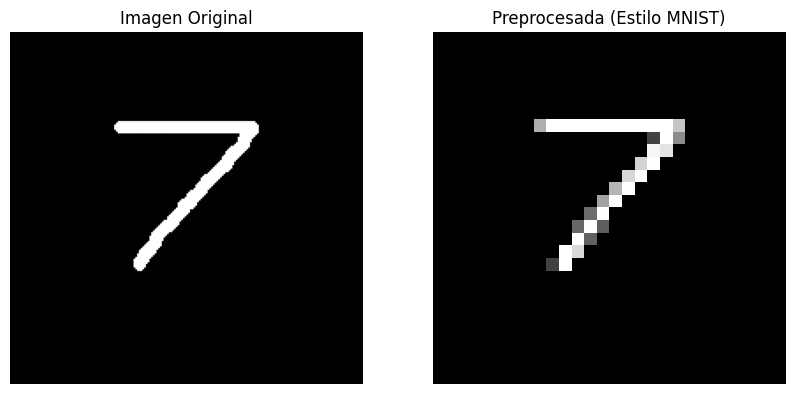


--- Predicciones ---
Red Densa: 7 con 97.45% de probabilidad.
Red Convolucional: 7 con 84.14% de probabilidad.



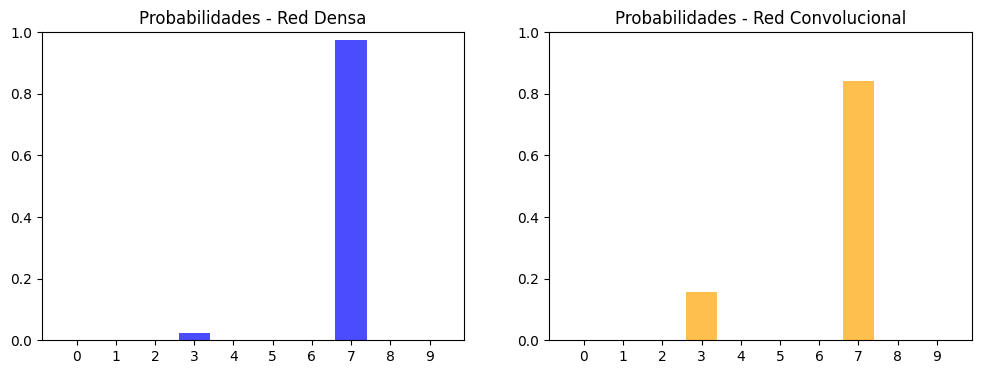

In [23]:
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt
import os

def predecir_imagen_externa(ruta_imagen):
    if not os.path.exists(ruta_imagen):
        print(f"El archivo no existe en la ruta: {ruta_imagen}")
        print("Por favor, sube una imagen al entorno de Colab y pasa la ruta correcta.")
        return

    # 1. Cargar imagen y convertir a escala de grises
    img_original = Image.open(ruta_imagen)
    img_gray = img_original.convert('L')

    # 2. Redimensionar a 28x28 píxeles
    img_resized = img_gray.resize((28, 28), Image.Resampling.LANCZOS)

    # Convertir a float32 para evitar desbordamientos durante los cálculos
    datos = np.array(img_resized).astype('float32')

    # 3. Detectar fondo blanco usando el promedio de toda la imagen de forma infalible
    promedio_imagen = np.mean(datos)
    if promedio_imagen > 127.0:
        # Si la media es clara, asumimos fondo blanco y número oscuro -> invertimos
        img_processed = ImageOps.invert(img_resized)
    else:
        img_processed = img_resized

    # Convertir a array numpy y normalizar a rango [0, 1]
    img_array = np.array(img_processed).astype('float32') / 255.0

    # Aplicar un ajuste de contraste/umbral suave:
    # Se limpian los ruidos de fondo (menores a 0.2) poniéndolos a 0.0
    # e incrementamos el contraste del trazo escalando los valores activos
    img_array = np.where(img_array < 0.2, 0.0, img_array)
    img_array = np.clip(img_array * 1.3, 0.0, 1.0)

    # 4. Preparar entradas específicas para cada modelo
    input_dense = img_array.reshape(1, 784)
    input_conv = img_array.reshape(1, 28, 28, 1)

    # 5. Realizar predicciones
    pred_dense = model_dense.predict(input_dense)[0]
    pred_conv = model_conv.predict(input_conv)[0]

    clase_dense = np.argmax(pred_dense)
    prob_dense = pred_dense[clase_dense] * 100

    clase_conv = np.argmax(pred_conv)
    prob_conv = pred_conv[clase_conv] * 100

    # 6. Visualización lado a lado
    fig, axs = plt.subplots(1, 2, figsize=(10, 5))

    axs[0].imshow(img_original)
    axs[0].set_title("Imagen Original")
    axs[0].axis('off')

    axs[1].imshow(img_array, cmap='gray')
    axs[1].set_title("Preprocesada (Estilo MNIST)")
    axs[1].axis('off')

    plt.show()

    # Mostrar resultados numéricos
    print(f"\n--- Predicciones ---")
    print(f"Red Densa: {clase_dense} con {prob_dense:.2f}% de probabilidad.")
    print(f"Red Convolucional: {clase_conv} con {prob_conv:.2f}% de probabilidad.\n")

    # Mostrar barras de distribución de probabilidad
    fig, axs_prob = plt.subplots(1, 2, figsize=(12, 4))
    classes = [str(i) for i in range(10)]

    axs_prob[0].bar(classes, pred_dense, color='blue', alpha=0.7)
    axs_prob[0].set_title("Probabilidades - Red Densa")
    axs_prob[0].set_ylim(0, 1)

    axs_prob[1].bar(classes, pred_conv, color='orange', alpha=0.7)
    axs_prob[1].set_title("Probabilidades - Red Convolucional")
    axs_prob[1].set_ylim(0, 1)

    plt.show()

# Ejemplo de uso con imagen:
predecir_imagen_externa("/content/mi_digito.png")